# Tarvo · análise exploratória dos dados ingeridos (set/2026)

Lê **somente** as tabelas de `data/` (geradas por `python -m src.ingestao`), já com o mapeamento de ECs da Helena em `config/mapeamento_ec.csv` (R19 do `HIPOTESES.md`).

O `analise_setembro.ipynb` já cobre a conta do mês e testa as hipóteses H1–H12. Este notebook olha o que ele não olha:

1. **Qualidade e integridade** das tabelas ingeridas (chaves, vazios, cobertura de contrato e vigência).
2. **Perfil do checkout**: distribuições por faixa, parcela, bandeira, dia e lojista; comportamento de estornos e antecipações.
3. **Comissão e divergência** de checkout recalculadas com as regras confirmadas (R1, R2, R8, R13, R15) e o mapeamento novo.
4. **Anomalias** que ainda não estão em nenhuma lista.
5. **Remessa e bancos**: perfil e a divergência de spread com o "padrão" = 1,5% (R17, R18).

Os números são exploratórios: a saída oficial será gerada pelo módulo de cálculo, com rastro.

In [1]:
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

DATA = Path("data")
assert DATA.exists(), "Rode antes: python -m src.ingestao --mes 2026-09 --entrada . --saida data"


def ler(nome, num=(), datas=()):
    df = pd.read_csv(DATA / f"{nome}.csv", sep=";", dtype=str, keep_default_na=False)
    for c in num:
        df[c] = pd.to_numeric(df[c].replace("", pd.NA))
    for c in datas:
        df[c] = pd.to_datetime(df[c].replace("", pd.NA), format="%Y-%m-%d")
    return df


TAXAS = ["taxa_debito_pct", "taxa_credito_vista_pct", "taxa_credito_2_6x_pct", "taxa_credito_7_12x_pct",
         "taxa_pix_pct", "taxa_antecipacao_pct"]
COL_FAIXA = dict(zip(["debito", "credito_a_vista", "credito_2_6x", "credito_7_12x", "pix", "antecipacao"], TAXAS))

lojista = ler("dim_lojista")
ec = ler("dim_ec", num=["n_linhas_orbe"])
contrato = ler("dim_contrato_taxa", num=["spread_remessa_pct"], datas=["vigencia_ini", "vigencia_fim"])
plano = ler("dim_plano_contas")
orbe = ler("fato_orbe", num=["parcelas", "valor_bruto", "taxa_aplicada_pct", "valor_taxa", "valor_liquido"],
           datas=["data_movimento", "data_venda_original", "data_taxa_ref"])
ponte = ler("fato_ponte", num=["valor_me", "taxa_cliente", "ptax", "valor_brl", "spread_brl", "spread_pct",
                               "spread_estimado_brl", "iof_brl"], datas=["data_contratacao", "data_liquidacao"])
banco = ler("fato_banco", num=["valor", "saldo"], datas=["data"])

# Gráficos: uma cor de série, tinta neutra para texto, grade recessiva.
AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 9, "axes.titlesize": 11, "axes.titlecolor": TINTA, "axes.titleweight": "bold"})
print({n: len(df) for n, df in [("dim_lojista", lojista), ("dim_ec", ec), ("dim_contrato_taxa", contrato),
                                ("dim_plano_contas", plano), ("fato_orbe", orbe), ("fato_ponte", ponte), ("fato_banco", banco)]})

{'dim_lojista': 25, 'dim_ec': 22, 'dim_contrato_taxa': 25, 'dim_plano_contas': 52, 'fato_orbe': 1943, 'fato_ponte': 233, 'fato_banco': 184}


## 1. Qualidade e integridade das tabelas

### 1.1 Vazios por coluna
Vazio só é problema onde a coluna deveria vir sempre preenchida. Os esperados estão explicados abaixo da tabela.

In [2]:
brutas = {n: pd.read_csv(DATA / f"{n}.csv", sep=";", dtype=str, keep_default_na=False)
          for n in ["dim_lojista", "dim_ec", "dim_contrato_taxa", "fato_orbe", "fato_ponte", "fato_banco"]}
vazios = pd.DataFrame([{"tabela": n, "coluna": c, "vazios": int((df[c] == "").sum()), "linhas": len(df)}
                       for n, df in brutas.items() for c in df.columns if (df[c] == "").any()])
vazios

,tabela,coluna,vazios,linhas
0,dim_lojista,cnpj,1,25
1,dim_lojista,nomes_alternativos,2,25
2,dim_lojista,ecs,3,25
3,dim_lojista,obs_tabela,17,25
4,dim_lojista,linha_planilha,1,25
5,dim_ec,cnpj,1,22
6,dim_ec,nome_tabela,4,22
7,dim_ec,sugestao_cnpj,22,22
8,dim_ec,sugestao_nome_tabela,22,22
9,dim_ec,observacao,18,22


Leitura:
- `fato_orbe.cnpj` vazio em **57 linhas** = a Atlas (RETIDO, R3). Os outros 21 ECs têm CNPJ.
- `modalidade`/`parcelas` vazios em 44 linhas = as antecipações e reversões (não têm modalidade). `bandeira` vazia em 227 = Pix (183) + antecipações (44).
- `dim_contrato_taxa`: 2 linhas sem taxa de checkout = Ponte Aérea e Nórdica ("só remessa"); 14 spreads vazios = "padrão" (R18).
- `dim_ec.nome_tabela` vazio em 4: a Atlas e os **3 ECs mapeados pelo `config/`** (a ingestão só preenche o nome quando o EC está na planilha). O CNPJ está certo, então o join funciona; é só cosmético.
- `fato_banco.saldo` vazio em 100 = todo o Meridiano (o OFX não traz saldo por linha).

### 1.2 Chaves e cobertura de contrato
Toda transação de EC confirmado precisa achar **exatamente uma** linha de contrato vigente na `data_taxa_ref`, com taxa preenchida na faixa dela. Se isso falhar, a comissão não sai.

In [3]:
ct = contrato.copy()
ct["ini"] = ct.vigencia_ini.fillna(pd.Timestamp("1900-01-01"))
ct["fim"] = ct.vigencia_fim.fillna(pd.Timestamp("2100-12-31"))
conf = orbe[orbe.status_ec == "CONFIRMADO"]
x = conf.merge(ct[["cnpj", "ini", "fim", "nome_tabela"] + TAXAS], on="cnpj", how="left")
x = x[(x.data_taxa_ref >= x.ini) & (x.data_taxa_ref <= x.fim)].copy()
n_ct = x.groupby("id_transacao").size()
x["taxa_contratada"] = [r[COL_FAIXA[r.faixa]] for _, r in x.iterrows()]
x["taxa_contratada"] = pd.to_numeric(x.taxa_contratada.replace("", pd.NA))

checks = pd.Series({
    "id_transacao único": orbe.id_transacao.is_unique,
    "todo EC da Orbe está em dim_ec": set(orbe.ec) <= set(ec.ec),
    "CNPJ do fato = CNPJ do dim_ec": (orbe.merge(ec[["ec", "cnpj"]], on="ec", suffixes=("", "_ec")).pipe(lambda m: (m.cnpj == m.cnpj_ec).all())),
    "todo CNPJ confirmado tem contrato": set(ec[ec.status == "CONFIRMADO"].cnpj) <= set(contrato.cnpj),
    "transações confirmadas": len(conf),
    "… com exatamente 1 contrato vigente": int((n_ct == 1).sum()),
    "… com taxa contratada vazia na faixa": int(x.taxa_contratada.isna().sum()),
    "num_op da Ponte único (sem a duplicata)": ponte[ponte.flag_duplicata != "S"].num_op.is_unique,
    "todo CNPJ da Ponte está na tabela": set(ponte.cnpj) <= set(contrato.cnpj),
    "(banco, ref_origem) único": not banco.duplicated(["banco", "ref_origem"]).any(),
})
checks.to_frame("resultado")

,resultado
id_transacao único,True
todo EC da Orbe está em dim_ec,True
CNPJ do fato = CNPJ do dim_ec,True
todo CNPJ confirmado tem contrato,True
transações confirmadas,1886
… com exatamente 1 contrato vigente,1886
… com taxa contratada vazia na faixa,0
num_op da Ponte único (sem a duplicata),True
todo CNPJ da Ponte está na tabela,True
"(banco, ref_origem) único",True


In [4]:
print("Estabelecimentos (dim_ec):", ec.status.value_counts().to_dict())
print("Linhas da Orbe por status:", orbe.status_ec.value_counts().to_dict())
print("Lojistas por linha de negócio (checkout, remessa):", lojista.groupby(["linha_checkout", "linha_remessa"]).size().to_dict())
print("data_taxa_ref ≠ data_movimento:", orbe[orbe.data_taxa_ref != orbe.data_movimento].tipo_lancamento.value_counts().to_dict())

Estabelecimentos (dim_ec): {'CONFIRMADO': 21, 'RETIDO': 1}
Linhas da Orbe por status: {'CONFIRMADO': 1886, 'RETIDO': 57}
Lojistas por linha de negócio (checkout, remessa): {('N', 'S'): 2, ('S', 'N'): 11, ('S', 'S'): 12}
data_taxa_ref ≠ data_movimento: {'ESTORNO': 59, 'REVERSAO ANTECIPACAO': 6}


**Resultado:** a ingestão está íntegra. Todas as **1.886 transações de ECs confirmados** acham exatamente um contrato vigente com taxa na faixa; só a Atlas (57 linhas) fica de fora, como deve. A `data_taxa_ref` já aplica a R2: nos 59 estornos e nas 6 reversões, ela é a data da operação original.

## 2. Perfil do checkout

### 2.1 Tamanho por tipo de lançamento

In [5]:
orbe.groupby("tipo_lancamento").valor_bruto.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
tipo_lancamento,,,,,,,,
ANTECIPACAO,38.0,38210.04,16258.44,4424.78,28268.56,41547.14,52221.16,58091.92
ESTORNO,59.0,-3666.88,3755.93,-18336.29,-4776.92,-2335.28,-989.96,-360.90
REVERSAO ANTECIPACAO,6.0,-48101.06,6970.49,-56350.28,-52349.95,-50178.30,-42026.78,-39516.03
VENDA,1840.0,3559.35,3640.72,112.76,1076.92,2361.36,4740.84,28000.00


### 2.2 Vendas por faixa, parcelas e bandeira

In [6]:
v = orbe[orbe.tipo_lancamento == "VENDA"].copy()
por_faixa = v.groupby("faixa").valor_bruto.agg(vendas="count", bruto="sum", ticket_medio="mean", mediana="median", maximo="max").round(2)
por_faixa["% do bruto"] = (100 * por_faixa.bruto / por_faixa.bruto.sum()).round(1)
display(por_faixa.sort_values("bruto", ascending=False))
print("Parcelas no crédito parcelado:", v[v.modalidade == "CREDITO PARCELADO"].parcelas.value_counts().sort_index().astype(int).to_dict())
print("Parcelas fora do esperado (à vista ≠ 1 ou parcelado < 2):",
      int(((v.modalidade == "CREDITO A VISTA") & (v.parcelas != 1)).sum() + ((v.modalidade == "CREDITO PARCELADO") & (v.parcelas < 2)).sum()))
display(pd.crosstab(v.faixa, v.bandeira.replace("", "(Pix)")))
taxas_por_bandeira = v.groupby(["ec", "faixa"]).agg(taxas=("taxa_aplicada_pct", "nunique"), bandeiras=("bandeira", "nunique"))
print("Pares (EC, faixa) com mais de uma taxa aplicada:", taxas_por_bandeira[taxas_por_bandeira.taxas > 1].index.tolist())

,vendas,bruto,ticket_medio,mediana,maximo,% do bruto
faixa,,,,,,
credito_7_12x,323,2738539.84,8478.45,7510.89,28000.00,41.8
credito_2_6x,597,2579017.05,4319.96,3677.44,18778.58,39.4
credito_a_vista,575,966500.34,1680.87,1448.22,6490.11,14.8
pix,177,182618.90,1031.75,895.14,3406.97,2.8
debito,168,82523.09,491.21,448.30,1336.57,1.3


Parcelas no crédito parcelado: {2.0: 143, 3.0: 98, 4.0: 123, 5.0: 119, 6.0: 114, 7.0: 50, 8.0: 51, 9.0: 60, 10.0: 50, 11.0: 59, 12.0: 53}
Parcelas fora do esperado (à vista ≠ 1 ou parcelado < 2): 0


bandeira,(Pix),AMEX,ELO,HIPERCARD,MASTERCARD,VISA
faixa,,,,,,
credito_2_6x,0,103,123,120,124,127
credito_7_12x,0,71,64,59,69,60
credito_a_vista,0,119,119,115,107,115
debito,0,37,31,25,43,32
pix,177,0,0,0,0,0


Pares (EC, faixa) com mais de uma taxa aplicada: [('1074504011', 'credito_2_6x'), ('1074504011', 'credito_7_12x'), ('1074504011', 'credito_a_vista'), ('1075624862', 'credito_a_vista')]


- **O crédito parcelado é 81% do bruto** (2–6x e 7–12x somam R$ 5,3 mi de R$ 6,5 mi). O ticket médio do 7–12x (R$ 8,5 mil) é cinco vezes o do crédito à vista: intercâmbio é venda grande e parcelada.
- **A taxa não depende da bandeira.** Em todo par (EC, faixa) há uma taxa só, exceto os 4 pares já conhecidos (Rota Global ×3 e Bridge), e ali a segunda taxa explica-se por data, não por bandeira. A planilha também não tem bandeira: a chave do contrato é **(lojista, faixa, vigência)**.
- Nenhuma parcela fora do esperado.

### 2.3 Vendas por dia

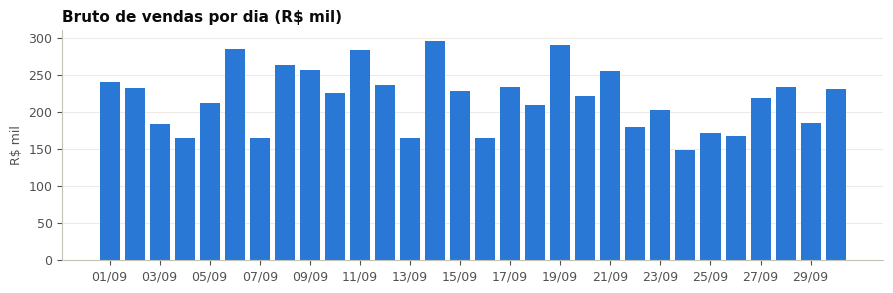

Vendas por dia da semana: {'Wednesday': 312, 'Tuesday': 309, 'Saturday': 258, 'Monday': 252, 'Sunday': 251, 'Friday': 237, 'Thursday': 221}
Bruto/dia: média R$ 218,306.64 | mín R$ 149,061.40 (24/09) | máx R$ 295,266.87 (14/09)
Vendas em 07/09 (feriado): 50


In [7]:
dia = v.groupby("data_movimento").valor_bruto.sum()
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(dia.index, dia.values / 1e3, color=AZUL, width=0.8)
ax.set_title("Bruto de vendas por dia (R$ mil)", loc="left")
ax.set_ylabel("R$ mil")
ax.grid(axis="x", visible=False)
fds = dia.index[dia.index.dayofweek >= 5]
ax.set_xticks(dia.index[::2])
ax.set_xticklabels([d.strftime("%d/%m") for d in dia.index[::2]], rotation=0)
plt.tight_layout(); plt.show()
print("Vendas por dia da semana:", v.data_movimento.dt.day_name().value_counts().to_dict())
print(f"Bruto/dia: média R$ {dia.mean():,.2f} | mín R$ {dia.min():,.2f} ({dia.idxmin():%d/%m}) | máx R$ {dia.max():,.2f} ({dia.idxmax():%d/%m})")
print("Vendas em 07/09 (feriado):", int((v.data_movimento == "2026-09-07").sum()))

A Orbe registra venda **todos os dias**, inclusive fins de semana e o feriado de 07/09, sem sazonalidade forte (R$ 149 mil a R$ 295 mil por dia). Os TEDs da Orbe na Aurora só caem em dia útil (seção 6), o que é coerente com uma liquidação defasada, mas a regra continua desconhecida (pergunta já aberta).

### 2.4 Concentração por lojista

In [8]:
por_ec = v.groupby("ec").valor_bruto.sum().sort_values(ascending=False)
print(f"{len(por_ec)} ECs com venda | maior: {100 * por_ec.iloc[0] / por_ec.sum():.1f}% do bruto | 5 maiores: {100 * por_ec.iloc[:5].sum() / por_ec.sum():.1f}%")
print("Faixas de ticket (vendas):", pd.cut(v.valor_bruto, [0, 500, 1000, 2500, 5000, 10000, 20000, 1e9],
                                           labels=["≤500", "500–1k", "1k–2,5k", "2,5k–5k", "5k–10k", "10k–20k", ">20k"]).value_counts().sort_index().to_dict())
v.nlargest(5, "valor_bruto")[["id_transacao", "data_movimento", "ec", "nome_estabelecimento", "faixa", "parcelas", "valor_bruto"]]

22 ECs com venda | maior: 8.9% do bruto | 5 maiores: 34.1%
Faixas de ticket (vendas): {'≤500': 135, '500–1k': 280, '1k–2,5k': 551, '2,5k–5k': 452, '5k–10k': 305, '10k–20k': 107, '>20k': 10}


,id_transacao,data_movimento,ec,nome_estabelecimento,faixa,parcelas,valor_bruto
889,TX88427296,2026-09-14,1038867654,KIWI EXPERIENCE TURISMO,credito_7_12x,10.0,28000.00
1108,TX88430012,2026-09-17,1043396662,HORIZONTE VIAGENS TURISMO,credito_7_12x,8.0,26213.84
924,TX88427030,2026-09-14,1043396662,HORIZONTE VIAGENS TURISMO,credito_7_12x,8.0,25477.57
882,TX88427045,2026-09-14,1000960410,OXFORD PREP CURSOS,credito_7_12x,11.0,22272.20
950,TX88428001,2026-09-15,1038867654,KIWI EXPERIENCE TURISMO,credito_7_12x,7.0,22224.39


Carteira **pulverizada**: nenhum lojista passa de 9% do bruto. As maiores vendas são todas de crédito 7–12x, e quatro das cinco maiores são de ECs que só entraram com o mapeamento da Helena (Kiwi e Horizonte Viagens).

### 2.5 Estornos

In [9]:
e = orbe[orbe.tipo_lancamento == "ESTORNO"].copy()
idx = orbe.set_index("id_transacao")
e["venda_no_arquivo"] = e.id_referencia.isin(idx.index)
e["dias_ate_estorno"] = (e.data_movimento - e.data_venda_original).dt.days
ee = e[e.venda_no_arquivo]
orig = idx.loc[ee.id_referencia]
print("Estornos:", len(e), "| venda original no arquivo:", int(e.venda_no_arquivo.sum()), "| de agosto:", int((~e.venda_no_arquivo).sum()))
print("Estorno é sempre TOTAL (|bruto| = bruto da venda):", int((ee.valor_bruto.abs().values == orig.valor_bruto.values).sum()), "de", len(ee))
print("Mesma faixa e mesma taxa da venda:", int(((ee.faixa.values == orig.faixa.values) & (ee.taxa_aplicada_pct.values == orig.taxa_aplicada_pct.values)).sum()), "de", len(ee))
print("Dias entre venda e estorno:", e.dias_ate_estorno.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
taxa_est = (e.groupby("ec").valor_bruto.sum().abs() / por_ec * 100).dropna().sort_values(ascending=False)
nome = ec.set_index("ec").nomes_orbe.str.split(" | ", regex=False).str[0]
print("\nEstorno como % do bruto vendido (5 maiores):")
taxa_est.head(5).round(2).rename(index=nome).to_frame("% estornado")

Estornos: 59 | venda original no arquivo: 50 | de agosto: 9
Estorno é sempre TOTAL (|bruto| = bruto da venda): 50 de 50
Mesma faixa e mesma taxa da venda: 50 de 50
Dias entre venda e estorno: {'min': 1.0, '50%': 5.0, 'mean': 6.8, 'max': 29.0}

Estorno como % do bruto vendido (5 maiores):


,% estornado
ec,
BAGAGEM LIVRE TURISMO,13.45
ROTA GLOBAL INTERCAMBIO,7.93
HORIZONTE INTERCAMBIO,5.36
LISBOA CURSOS E VIAGENS,5.10
MUNDO ABERTO INTERC LTDA,4.55


- **Todo estorno é total** e repete a faixa e a taxa da venda. Não há estorno parcial para tratar.
- Os 9 estornos de agosto estão espalhados em 9 lojistas diferentes (um em cada); o maior é Campus Global (R$ 8.917,21).
- **Bagagem Livre estornou 13,4% do que vendeu** no mês, quase o dobro do segundo colocado (Rota Global, 7,9%). Não muda a regra, mas é um ponto de atenção para o financeiro.

### 2.6 Antecipações e reversões

In [10]:
a = orbe[orbe.tipo_lancamento == "ANTECIPACAO"]
r = orbe[orbe.tipo_lancamento == "REVERSAO ANTECIPACAO"].merge(
    orbe[["id_transacao", "valor_bruto", "data_movimento"]], left_on="id_referencia", right_on="id_transacao", suffixes=("", "_orig"))
print("Reversões: |bruto| ÷ bruto da antecipação original:", (r.valor_bruto.abs() / r.valor_bruto_orig).round(4).tolist())
print("Reversões: dias após a antecipação:", (r.data_movimento - r.data_movimento_orig).dt.days.tolist())
liq_mes = orbe[orbe.tipo_lancamento.isin(["VENDA", "ESTORNO"])].groupby("ec").valor_liquido.sum()
ant = a.groupby("ec").valor_bruto.agg(antecipacoes="count", bruto_antecipado="sum")
ant["reversoes"] = r.groupby("ec").size()
ant["antecipado ÷ líquido vendido no mês"] = (ant.bruto_antecipado / liq_mes).round(2)
ant.rename(index=nome).fillna({"reversoes": 0}).sort_values("antecipado ÷ líquido vendido no mês", ascending=False)

Reversões: |bruto| ÷ bruto da antecipação original: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Reversões: dias após a antecipação: [1, 3, 2, 2, 2, 2]


,antecipacoes,bruto_antecipado,reversoes,antecipado ÷ líquido vendido no mês
ec,,,,
ATLAS IDIOMAS,5,235943.10,2.0,1.82
OXFORD PREP CURSOS,8,351826.85,1.0,1.21
CANGURU INTERCAMBIO,4,131506.78,0.0,0.50
DUBLIN HUB INTERCAMBIO,4,119800.43,0.0,0.42
KIWI EXPERIENCE TURISMO,3,115783.42,2.0,0.39
CASA DO ESTUDANTE VIAG,4,134646.37,0.0,0.36
MAPLE STUDY,3,120692.58,0.0,0.33
EDU ABROAD CONSULTORIA,2,83708.13,0.0,0.26
MUNDO ABERTO INTERC LTDA,2,104471.79,1.0,0.19


- Toda reversão desfaz **100%** de uma antecipação, 1 a 3 dias depois.
- **A Atlas antecipou 1,8× o que vendeu no mês**: R$ 236 mil antecipados contra R$ 135 mil de vendas, sendo uma lojista que começou em 10/09 e **não tem contrato**. Duas das cinco antecipações dela foram revertidas (R$ 109 mil). Somado aos R$ 249 mil que a Aurora já pagou a ela em PIX, é o maior risco da carteira. Vale levar isso ao financeiro junto com a pergunta da Atlas.
- A Oxford também antecipou mais do que vendeu no mês (1,2×), o que é possível quando se antecipam parcelas de vendas antigas.

## 3. Comissão e divergência de checkout (regras confirmadas)

- Comissão por transação = `bruto × taxa contratada` (R1), arredondada meio para cima **por operação** (R8). Estorno e reversão entram negativos (R2, R13).
- Divergência = `bruto × (taxa aplicada − taxa contratada)` (R15), comparando percentuais (R14).
- Só ECs confirmados; Atlas fora (R3).

In [11]:
Q = Decimal("0.01")
x["comissao"] = [float((Decimal(str(b)) * Decimal(str(t)) / 100).quantize(Q, ROUND_HALF_UP)) for b, t in zip(x.valor_bruto, x.taxa_contratada)]
x["divergencia"] = [float(Decimal(str(b)) * (Decimal(str(ap)) - Decimal(str(t))) / 100) for b, ap, t in zip(x.valor_bruto, x.taxa_aplicada_pct, x.taxa_contratada)]
x["diverge"] = x.divergencia.abs() > 1e-9
res = (x.groupby("ec")
        .agg(nome_tabela=("nome_tabela", "first"), linhas=("id_transacao", "size"), bruto=("valor_bruto", "sum"), comissao=("comissao", "sum"),
             taxa_orbe=("valor_taxa", "sum"), linhas_div=("diverge", "sum"), divergencia=("divergencia", "sum"))
        .round(2).sort_values("comissao", ascending=False).reset_index())
display(res)
print(f"Comissão total: R$ {x.comissao.sum():,.2f} em {res.shape[0]} lojistas | taxa cobrada pela Orbe: R$ {x.valor_taxa.sum():,.2f}")
print("Comissão por tipo:", x.groupby("tipo_lancamento").comissao.sum().round(2).to_dict())
print(f"Divergência: R$ {x.divergencia.sum():,.2f} em {int(x.diverge.sum())} linhas")
print(f"Efeito do truncamento (comissão − taxa Orbe nas linhas sem divergência): R$ {(x.comissao - x.valor_taxa)[~x.diverge].sum():,.2f} em {int((~x.diverge).sum())} linhas")
x[x.diverge].groupby(["nome_tabela", "tipo_lancamento"]).divergencia.agg(["count", "sum"]).round(2)

,ec,nome_tabela,linhas,bruto,comissao,taxa_orbe,linhas_div,divergencia
0,1037647039,Mundo Aberto,168,609682.86,18522.09,18521.38,0,0.00
1,1000960410,Oxford Prep Cursos Ltda,98,611910.85,16077.90,16077.42,0,0.00
2,1074504011,Rota Global Intercâmbio Ltda,159,524231.98,15621.27,17166.83,87,1546.27
3,1018325654,Casa do Estudante Viagens Ltda,119,519678.45,15391.92,15391.27,0,0.00
4,1041180753,Maple Study Assessoria Educacional Ltda,105,496258.69,15010.78,15010.25,0,0.00
5,1020660828,EduAbroad,100,410680.95,12070.17,12069.64,0,0.00
6,1075624862,Escola Bridge de Idiomas Ltda,107,368871.13,11916.02,11945.46,5,29.95
7,1014537966,Dublin Hub Intercâmbio Ltda,111,415328.18,11906.08,11905.52,0,0.00
8,1061760196,Canguru,80,405055.67,11679.43,11679.08,0,0.00
9,1038867654,Kiwi Experience,85,328428.75,10711.41,10711.06,0,0.00


Comissão total: R$ 222,437.15 em 21 lojistas | taxa cobrada pela Orbe: R$ 224,004.31
Comissão por tipo: {'ANTECIPACAO': 25536.82, 'ESTORNO': -6992.34, 'REVERSAO ANTECIPACAO': -3777.78, 'VENDA': 207670.45}
Divergência: R$ 1,576.23 em 92 linhas
Efeito do truncamento (comissão − taxa Orbe nas linhas sem divergência): R$ 8.64 em 1794 linhas


count      sum
nome_tabela                  tipo_lancamento                
Bridge Idiomas (NOVA)        VENDA                5    29.95
Rota Global Intercâmbio Ltda ESTORNO              4   -98.44
                             VENDA               83  1644.71

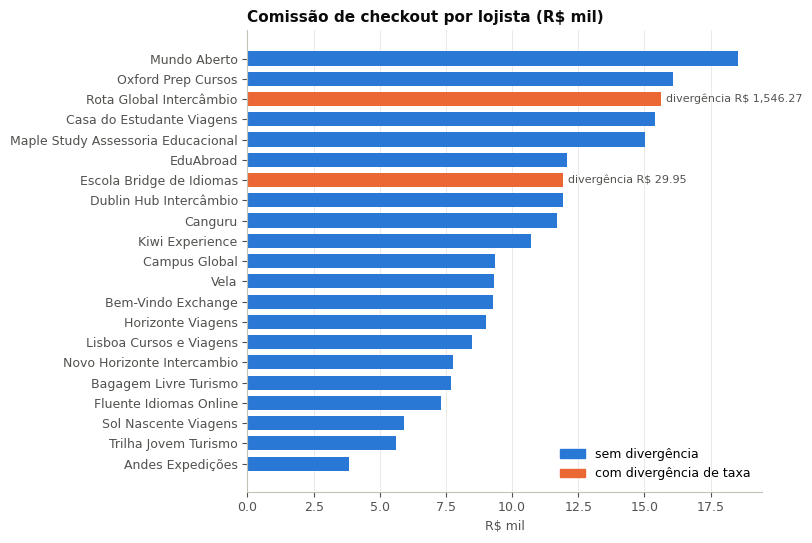

In [12]:
graf = res.sort_values("comissao")
fig, ax = plt.subplots(figsize=(8, 5.5))
cores = [LARANJA if d > 0 else AZUL for d in graf.linhas_div]
ax.barh(graf.nome_tabela.str.replace(" Ltda", ""), graf.comissao / 1e3, color=cores, height=0.7)
ax.set_title("Comissão de checkout por lojista (R$ mil)", loc="left")
ax.set_xlabel("R$ mil")
ax.grid(axis="y", visible=False)
for i, (c, d) in enumerate(zip(graf.comissao, graf.divergencia)):
    if d > 0:
        ax.text(c / 1e3 + 0.2, i, f"divergência R$ {d:,.2f}", va="center", color=TINTA2, fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="sem divergência"), Patch(color=LARANJA, label="com divergência de taxa")],
          loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

- **Comissão de checkout: R$ 222.437,15 em 21 lojistas**, sendo R$ 207,7 mil de vendas e R$ 25,5 mil de antecipações, menos R$ 7,0 mil de estornos e R$ 3,8 mil de reversões. A prévia anterior (R$ 194,9 mil em 18 lojistas) não tinha os três ECs da Helena.
- **Divergência: R$ 1.576,23 em 92 linhas**, só Rota Global (R$ 1.546,27; 83 vendas e 4 estornos) e Bridge (R$ 29,95; 5 vendas). Os três ECs novos não divergem.
- O truncamento da Orbe soma só R$ 8,64 em 1.794 linhas: confirma que ignorar centavos (R14) não esconde nada material.

## 4. Outras anomalias do checkout

In [13]:
redondas = v[v.valor_bruto % 100 == 0]
print("Vendas com valor redondo (múltiplo de R$ 100):")
display(redondas[["id_transacao", "data_movimento", "ec", "nome_estabelecimento", "faixa", "parcelas", "valor_bruto"]])
print("Mesmo EC, mesmo valor e mesmo dia (duplicata provável):", int(v.duplicated(["ec", "valor_bruto", "data_movimento"]).sum()))
mesmo_valor = v[v.duplicated(["ec", "valor_bruto"], keep=False)]
print("Mesmo EC e mesmo valor em dias diferentes:")
display(mesmo_valor[["id_transacao", "data_movimento", "ec", "nome_estabelecimento", "faixa", "valor_bruto"]])
print("Bandeiras nas linhas divergentes da Rota Global:", x[x.diverge & (x.ec == "1074504011")].bandeira.value_counts().to_dict())

Vendas com valor redondo (múltiplo de R$ 100):


,id_transacao,data_movimento,ec,nome_estabelecimento,faixa,parcelas,valor_bruto
889,TX88427296,2026-09-14,1038867654,KIWI EXPERIENCE TURISMO,credito_7_12x,10.0,28000.0


Mesmo EC, mesmo valor e mesmo dia (duplicata provável): 0
Mesmo EC e mesmo valor em dias diferentes:


,id_transacao,data_movimento,ec,nome_estabelecimento,faixa,valor_bruto
373,TX88416568,2026-09-06,1023622151,LISBOA CURSOS VIAGENS,credito_a_vista,1155.61
622,TX88421861,2026-09-10,1023622151,LISBOA CURSOS E VIAGENS,credito_2_6x,1155.61


Bandeiras nas linhas divergentes da Rota Global: {'AMEX': 25, 'ELO': 20, 'VISA': 18, 'HIPERCARD': 15, 'MASTERCARD': 9}


- **Uma única venda redonda** em 1.840: Kiwi, R$ 28.000,00 em 10x no dia 14/09, a maior venda do mês. Pode ser um pacote fechado, mas é atípica (todas as outras têm centavos). Sugestão: pendência informativa, sem bloquear a comissão.
- Nenhuma duplicata provável. O único par de mesmo valor (Lisboa, R$ 1.155,61) tem faixas e dias diferentes: coincidência.
- A taxa a mais da Rota Global aparece em **todas as bandeiras**, o que reforça que é uma mudança no cadastro do EC na Orbe, não um problema de bandeira.

## 5. Remessa (Ponte)

In [14]:
pu = ponte[ponte.flag_duplicata != "S"].copy()
display(pu.groupby("moeda").agg(operacoes=("num_op", "size"), valor_brl=("valor_brl", "sum"), spread_brl=("spread_brl", "sum"), iof_brl=("iof_brl", "sum")).round(2))
print("IOF ÷ valor R$ (%):", sorted((pu.iof_brl / pu.valor_brl * 100).round(2).unique()))
prazo = (pu.data_liquidacao - pu.data_contratacao).dt.days
print("Dias até a liquidação:", prazo.value_counts().to_dict(), "| contratações com D+3 caem em:", pu[prazo == 3].data_contratacao.dt.day_name().unique().tolist())
print("Liquidações em 07/09 (feriado):", int((pu.data_liquidacao == "2026-09-07").sum()))

,operacoes,valor_brl,spread_brl,iof_brl
moeda,,,,
AUD,48,839951.54,11329.45,3191.81
CAD,42,808431.03,10705.21,3072.06
EUR,33,1197532.31,16074.48,4550.62
GBP,36,1232906.53,17739.02,4685.05
NZD,37,604128.34,8218.05,2295.70
USD,36,907254.58,13185.50,3447.55


IOF ÷ valor R$ (%): [0.38]
Dias até a liquidação: {1: 186, 3: 46} | contratações com D+3 caem em: ['Friday']
Liquidações em 07/09 (feriado): 17


In [15]:
sp = contrato.drop_duplicates("cnpj").set_index("cnpj")[["nome_tabela", "spread_remessa_pct", "spread_remessa_regra"]]
sp["spread_contratado"] = sp.spread_remessa_pct.fillna(1.5)          # R18: vazio/"padrão" = 1,5% sobre a PTAX
pos = pu[pu.spread_brl > 0].join(sp, on="cnpj")
pos["dif_pp"] = (pos.spread_pct - pos.spread_contratado).round(3)
pos["divergencia_brl"] = pos.valor_me * pos.ptax * (pos.spread_pct - pos.spread_contratado) / 100   # R17
div_rem = (pos.groupby(["nome_tabela", "spread_remessa_regra"])
             .agg(operacoes=("num_op", "size"), contratado=("spread_contratado", "first"), aplicado_min=("spread_pct", "min"),
                  aplicado_max=("spread_pct", "max"), spread_brl=("spread_brl", "sum"), divergencia_brl=("divergencia_brl", "sum"))
             .round(3).sort_values("divergencia_brl", ascending=False))
display(div_rem)
fora = pos[pos.dif_pp.abs() > 0.01]
print(f"Operações com diferença real (> 0,01 p.p.): {len(fora)} | divergência R$ {fora.divergencia_brl.sum():,.2f} | lojistas: {fora.nome_tabela.unique().tolist()}")
comissao_rem = sum(float((Decimal(str(s)) / 2).quantize(Q, ROUND_HALF_UP)) for s in pos.spread_brl)
print(f"Comissão de remessa (50% por operação, sem negativos, sem a duplicata): R$ {comissao_rem:,.2f}")

,,operacoes,contratado,aplicado_min,aplicado_max,spread_brl,divergencia_brl
nome_tabela,spread_remessa_regra,,,,,,
Mundo Aberto,EXPLICITO,23,1.20,1.499,1.501,7095.25,1418.854
Rota Global Intercâmbio Ltda,EXPLICITO,28,1.50,1.499,1.501,9836.52,1.204
Canguru,PADRAO,22,1.50,1.499,1.501,7528.01,0.880
Ponte Aérea Estudantil Ltda,PADRAO,14,1.50,1.499,1.501,6014.55,0.771
EduAbroad,EXPLICITO,16,1.30,1.299,1.301,5040.46,0.530
Bagagem Livre Turismo Ltda,EXPLICITO,8,1.50,1.499,1.501,2585.33,0.425
Lisboa Cursos e Viagens Ltda,EXPLICITO,16,1.60,1.599,1.602,6392.62,0.151
Casa do Estudante Viagens Ltda,EXPLICITO,18,1.50,1.499,1.501,6151.74,0.111
Dublin Hub Intercâmbio Ltda,EXPLICITO,13,1.50,1.499,1.501,3545.15,0.070


Operações com diferença real (> 0,01 p.p.): 23 | divergência R$ 1,418.85 | lojistas: ['Mundo Aberto']
Comissão de remessa (50% por operação, sem negativos, sem a duplicata): R$ 39,543.45


- **IOF é sempre 0,38%** do valor em reais, e a liquidação é D+1, ou D+3 quando a contratação cai na sexta. A Ponte liquidou operações **em 07/09 (feriado)**: dá para conferir com o TED do dia no Meridiano, mas não muda número.
- **Com o "padrão" = 1,5% (R18), só a Mundo Aberto diverge**: 23 operações a 1,50% contra 1,20% contratado, **R$ 1.418,85** pelo valor cheio (R17). Kiwi, Canguru e Ponte Aérea, que estavam em branco ou "padrão", batem exatamente. As demais diferenças são de arredondamento do Spread % (±0,002 p.p., menos de R$ 1,30 por lojista no mês).
- A comissão de remessa (R$ 39.543,45) bate com a prévia do time.

## 6. Bancos

In [16]:
display(banco.groupby(["banco", "tipo_lancamento"]).valor.agg(["count", "sum"]).round(2))
fds = banco[banco.data.dt.dayofweek >= 5]
print("Lançamentos com data em sábado/domingo:")
display(fds[["banco", "ref_origem", "data", "descricao", "valor"]])
ted = banco[(banco.banco == "AURORA") & banco.descricao.str.contains("ORBE")]
print("TEDs da Orbe: só em dia útil?", bool((ted.data.dt.dayofweek < 5).all()), "| em 07/09:", int((ted.data == "2026-09-07").sum()), "| quantidade:", len(ted))

count         sum
banco     tipo_lancamento                        
AURORA    BOLETO CONDOMINIO         1   -28450.00
          CARTAO PJ                 1    -2210.00
          DEB AUT                   1   -41208.77
          DEBITO DARF               3   -77198.01
          DEVOLUCAO PIX             1    12400.00
          GPS INSS                  1   -51320.66
          GRF FGTS                  1   -14778.57
          PAGTO ISS                 1   -21877.40
          PAGTO SALARIOS            1  -184732.18
          PIX ENVIADO              45 -4237067.61
          PIX RECEBIDO              1     7350.00
          TAR PACOTE                1     -389.00
          TAR TED                   1     -187.50
          TED RECEBIDA             21  3557246.29
          TRANSF ENTRE              4 -1450000.00
MERIDIANO APLICACAO AUTOMATICA      3  -588124.00
          IOF S                     1      -48.21
          PIX RECEB                64  5629687.12
          RENDIMENTO APLIC          1     3912.66
          RESGATE AUTOMATICO        3   472881.00
          SEGURO EMPRESARIAL        1    -1830.44
          TARIFA MANUTENCAO         1     -129.90
          TARIFA PACOTE             1     -450.00
          TED ENVIADA              21 -5611447.12
          TED RECEB                 1    61884.12
          TED RECEBIDA              3  1150000.00

Lançamentos com data em sábado/domingo:


,banco,ref_origem,data,descricao,valor
7,AURORA,L16,2026-09-05,BOLETO CONDOMINIO ED. FARIA LIMA 3311,-28450.00
104,MERIDIANO,MRD2026090143,2026-09-05,APLICACAO AUTOMATICA CDB DI,-161736.00
125,MERIDIANO,MRD2026090292,2026-09-12,SEGURO EMPRESARIAL PARC 09/12,-1830.44
147,MERIDIANO,MRD2026090445,2026-09-19,RESGATE AUTOMATICO CDB DI,163936.00
167,MERIDIANO,MRD2026090586,2026-09-26,IOF S/ OPERACAO CREDITO,-48.21


TEDs da Orbe: só em dia útil? True | em 07/09: 0 | quantidade: 21


- **5 lançamentos datados em sábado** (condomínio na Aurora; aplicação, resgate, seguro e IOF no Meridiano). Bancos não costumam lançar no sábado: provavelmente é a data de agendamento. Não muda valor, mas o validador de período não deve tratar sábado como erro.
- Os TEDs da Orbe só caem em dia útil e pulam o feriado de 07/09.

## 7. O que fica

**Ingestão**
- Íntegra: chaves únicas, todo EC confirmado com exatamente um contrato vigente e taxa na faixa, `data_taxa_ref` já aplicando a R2. Único detalhe: `dim_ec.nome_tabela` vazio nos ECs mapeados pelo `config/`.

**Checkout (números para a saída)**
- **Comissão: R$ 222.437,15 em 21 lojistas** (Atlas fora).
- **Divergência: R$ 1.576,23 em 92 linhas** (Rota Global R$ 1.546,27; Bridge R$ 29,95).
- A chave do contrato é (lojista, faixa, vigência). A bandeira não entra.
- Todo estorno é total e herda faixa e taxa da venda. Toda reversão desfaz 100% da antecipação.

**Remessa**
- Comissão R$ 39.543,45. **Divergência: só Mundo Aberto, R$ 1.418,85** (o "padrão" = 1,5% fechou Kiwi, Canguru e Ponte Aérea).

**Pontos novos para levar ao financeiro**
1. **Atlas**: antecipou R$ 236 mil (1,8× as vendas do mês) sem contrato, com R$ 109 mil revertidos e R$ 249 mil já pagos em PIX.
2. **Bagagem Livre**: estornou 13,4% do que vendeu, quase o dobro do segundo colocado.
3. **Kiwi**: venda redonda de R$ 28.000,00 em 10x (14/09), a maior do mês e a única sem centavos.
4. Ponte liquidando operações no feriado de 07/09, e 5 lançamentos bancários datados em sábado (informativo).